In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

!wget $data -O data-week-3.csv

--2026-10-25 12:16:16--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954.59K  --.-KB/s    in 0.005s  

2026-10-25 12:16:16 (196 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



In [50]:
df = pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [51]:
df.columns = df.columns.str.lower()
df.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [52]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges            str
churn                   str
dtype: object

In [53]:
#convert all strings to lower and replace spaces with _
cat_cols = list(df.dtypes[df.dtypes=='str'].index)

for c in cat_cols:
    df[c] = df[c].str.lower().str.replace(' ','')

In [54]:
df.to_csv('data-week-3-tidyed.csv', index=False)

In [55]:
df = pd.read_csv('data-week-3-tidyed.csv')
df.head(10)

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,nophoneservice,dsl,no,...,no,no,no,no,month-to-month,yes,electroniccheck,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,oneyear,no,mailedcheck,56.95,1889.50,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailedcheck,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,nophoneservice,dsl,yes,...,yes,yes,no,no,oneyear,no,banktransfer(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiberoptic,no,...,no,no,no,no,month-to-month,yes,electroniccheck,70.70,151.65,yes
5,9305-cdskc,female,0,no,no,8,yes,yes,fiberoptic,no,...,yes,no,yes,yes,month-to-month,yes,electroniccheck,99.65,820.50,yes
6,1452-kiovk,male,0,no,yes,22,yes,yes,fiberoptic,no,...,no,no,yes,no,month-to-month,yes,creditcard(automatic),89.10,1949.40,no
7,6713-okomc,female,0,no,no,10,no,nophoneservice,dsl,yes,...,no,no,no,no,month-to-month,no,mailedcheck,29.75,301.90,no
8,7892-pookp,female,0,yes,no,28,yes,yes,fiberoptic,no,...,yes,yes,yes,yes,month-to-month,yes,electroniccheck,104.80,3046.05,yes
9,6388-tabgu,male,0,no,yes,62,yes,no,dsl,yes,...,no,no,no,no,oneyear,no,banktransfer(automatic),56.15,3487.95,no


In [56]:
df.dtypes

customerid              str
gender                  str
seniorcitizen         int64
partner                 str
dependents              str
tenure                int64
phoneservice            str
multiplelines           str
internetservice         str
onlinesecurity          str
onlinebackup            str
deviceprotection        str
techsupport             str
streamingtv             str
streamingmovies         str
contract                str
paperlessbilling        str
paymentmethod           str
monthlycharges      float64
totalcharges        float64
churn                   str
dtype: object

In [57]:
df['seniorcitizen'].value_counts()

seniorcitizen
0    5901
1    1142
Name: count, dtype: int64

In [58]:
df.isnull().sum()

customerid           0
gender               0
seniorcitizen        0
partner              0
dependents           0
tenure               0
phoneservice         0
multiplelines        0
internetservice      0
onlinesecurity       0
onlinebackup         0
deviceprotection     0
techsupport          0
streamingtv          0
streamingmovies      0
contract             0
paperlessbilling     0
paymentmethod        0
monthlycharges       0
totalcharges        11
churn                0
dtype: int64

In [59]:
df[df['totalcharges'].isnull()]

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
488,4472-lvygi,female,0,yes,yes,0,no,nophoneservice,dsl,yes,...,yes,yes,yes,no,twoyear,yes,banktransfer(automatic),52.55,NaN,no
753,3115-czmzd,male,0,no,yes,0,yes,no,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,20.25,NaN,no
936,5709-lvoeq,female,0,yes,yes,0,yes,no,dsl,yes,...,yes,no,yes,yes,twoyear,no,mailedcheck,80.85,NaN,no
1082,4367-nuyao,male,0,yes,yes,0,yes,yes,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,25.75,NaN,no
1340,1371-dwpaz,female,0,yes,yes,0,no,nophoneservice,dsl,yes,...,yes,yes,yes,no,twoyear,no,creditcard(automatic),56.05,NaN,no
3331,7644-omvmy,male,0,yes,yes,0,yes,no,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,19.85,NaN,no
3826,3213-vvolg,male,0,yes,yes,0,yes,yes,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,25.35,NaN,no
4380,2520-sgtta,female,0,yes,yes,0,yes,no,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,20.00,NaN,no
5218,2923-arzlg,male,0,yes,yes,0,yes,no,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,oneyear,yes,mailedcheck,19.70,NaN,no
6670,4075-wkniu,female,0,yes,yes,0,yes,yes,dsl,no,...,yes,yes,yes,no,twoyear,no,mailedcheck,73.35,NaN,no


In [60]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors="coerce")
df.totalcharges = df.totalcharges.fillna(0)
df.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [61]:
df.churn.value_counts()

churn
no     5174
yes    1869
Name: count, dtype: int64

In [62]:
df.churn = (df.churn=='yes').astype(int)

In [63]:
df.to_csv('data-week-3-tidyed.csv', index=False)
df.churn.value_counts()

churn
0    5174
1    1869
Name: count, dtype: int64

**Validation**

In [64]:
from sklearn.model_selection import train_test_split

In [65]:
#It is done this way so we have a training set that includes training and validation.
df_full_train, df_test = train_test_split(df,test_size=0.2, random_state=1)
len(df), len(df_full_train), len(df_test)

(7043, 5634, 1409)

In [66]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
len(df), len(df_full_train), len(df_test), len(df_val), len(df_train)

(7043, 5634, 1409, 1409, 4225)

In [67]:
#Above randomises, with seed of 1
df_train.head()
#reset indexes
df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)
df_full_train.reset_index(drop=True, inplace=True)
df_train.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,8015-ihcgw,female,0,yes,yes,72,yes,yes,fiberoptic,yes,...,yes,yes,yes,yes,twoyear,yes,electroniccheck,115.50,8425.15,0
1,1960-uycnn,male,0,no,no,10,yes,yes,fiberoptic,no,...,yes,no,no,yes,month-to-month,yes,electroniccheck,95.25,1021.55,0
2,9250-wypll,female,0,no,no,5,yes,yes,fiberoptic,no,...,no,no,no,no,month-to-month,no,electroniccheck,75.55,413.65,1
3,6786-obwqr,female,0,yes,yes,5,yes,no,fiberoptic,no,...,no,no,yes,no,month-to-month,yes,electroniccheck,80.85,356.10,0
4,1328-euzhc,female,0,yes,no,18,yes,no,no,nointernetservice,...,nointernetservice,nointernetservice,nointernetservice,nointernetservice,twoyear,no,mailedcheck,20.10,370.50,0


In [68]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

**EDA**

In [69]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [70]:
df.churn.value_counts(normalize=True)#shows as percentage

churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

In [71]:
df.churn.mean()

np.float64(0.2653698707936959)

In [72]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

**Risk**

In [73]:
global_churn = df_full_train.churn.mean()

In [74]:
churn_female = df_full_train[df_full_train.gender=='female'].churn.mean()
churn_male = df_full_train[df_full_train.gender=='male'].churn.mean()
churn_female, churn_male

(np.float64(0.27682403433476394), np.float64(0.2632135306553911))

In [75]:
#low churn so not much of a predicter
global_churn - churn_female

np.float64(-0.006855983216553063)

In [76]:
#not much of a predictor
global_churn-churn_male

np.float64(0.006754520462819769)

In [77]:
df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

In [78]:
#much more of a predictor
churn_partner = df_full_train[df_full_train.partner=='yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner=='no'].churn.mean()
churn_partner, churn_no_partner

(np.float64(0.20503330866025166), np.float64(0.3298090040927694))

In [79]:
global_churn - churn_partner#0.06493474245795922
global_churn-churn_no_partner#-0.12477569543251776

np.float64(-0.05984095297455855)

In [80]:
#customer with n partner are 22% more likely to switch(churn)
churn_no_partner / global_churn

np.float64(1.2216593879412643)

In [81]:
#customer with partner 25% less likely to switch(churn)
churn_partner / global_churn

np.float64(0.7594724924338315)

In [82]:
from IPython.display import display

print('Risk >1 more likely to switch, <1 less likely')

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean','count'])
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    df_group['global'] = global_churn
    display(df_group)
    print()
    print()

Risk >1 more likely to switch, <1 less likely
gender


,mean,count,diff,risk,global
gender,,,,,
female,0.276824,2796,0.006856,1.025396,0.269968
male,0.263214,2838,-0.006755,0.974980,0.269968




seniorcitizen


,mean,count,diff,risk,global
seniorcitizen,,,,,
0,0.242270,4722,-0.027698,0.897403,0.269968
1,0.413377,912,0.143409,1.531208,0.269968




partner


...

,mean,count,diff,risk,global
contract,,,,,
month-to-month,0.431701,3104,0.161733,1.599082,0.269968
oneyear,0.120573,1186,-0.149395,0.446621,0.269968
twoyear,0.028274,1344,-0.241694,0.104730,0.269968




paperlessbilling


,mean,count,diff,risk,global
paperlessbilling,,,,,
no,0.172071,2313,-0.097897,0.637375,0.269968
yes,0.338151,3321,0.068183,1.252560,0.269968




paymentmethod


,mean,count,diff,risk,global
paymentmethod,,,,,
banktransfer(automatic),0.168171,1219,-0.101797,0.622928,0.269968
creditcard(automatic),0.164339,1217,-0.105630,0.608733,0.269968
electroniccheck,0.455890,1893,0.185922,1.688682,0.269968
mailedcheck,0.193870,1305,-0.076098,0.718121,0.269968


**Mutual info**  
Interaction between churn and features

In [87]:
from sklearn.metrics import mutual_info_score

mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [88]:
def mutual_info_churn_score(series):
    return mutual_info_score(df_full_train.churn, series)

mi = df_full_train[categorical].apply(mutual_info_churn_score)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [89]:
list(mi.sort_values(ascending=False).index)

['contract',
 'onlinesecurity',
 'techsupport',
 'internetservice',
 'onlinebackup',
 'deviceprotection',
 'paymentmethod',
 'streamingtv',
 'streamingmovies',
 'paperlessbilling',
 'dependents',
 'partner',
 'seniorcitizen',
 'multiplelines',
 'phoneservice',
 'gender']

<Axes: >

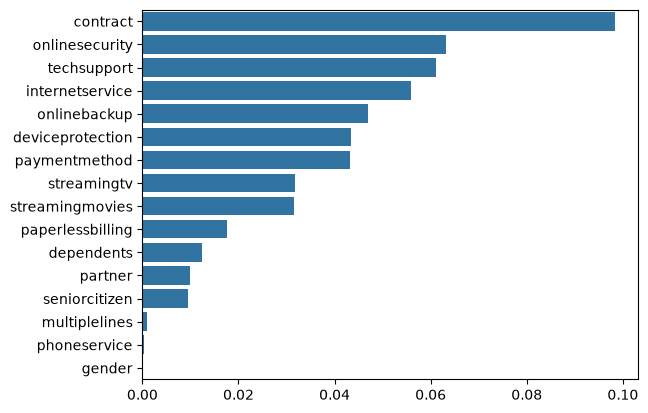

In [90]:
import seaborn as sns
sns.barplot(mi,order=list(mi.sort_values(ascending=False).index), orient='h')

**Correlation**

In [91]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

*Tenure has a medium negative correlation. The longer customers stay with the company, the less likely they are to churn.*  
*Monthly charges have a low-to-medium positive correlation: the more customers pay per month, the more likely they are to churn.*  
*Total charges have a low-to-medium negative correlation - not surprising, since total charges accumulate with tenure.*

In [35]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

In [92]:
df_full_train.tenure.max()

np.int64(72)

In [93]:
df_full_train.tenure.value_counts()

tenure
1     485
72    283
2     194
3     165
71    147
     ... 
45     46
21     45
39     43
36     38
0       8
Name: count, Length: 73, dtype: int64

<Axes: xlabel='tenure', ylabel='Count'>

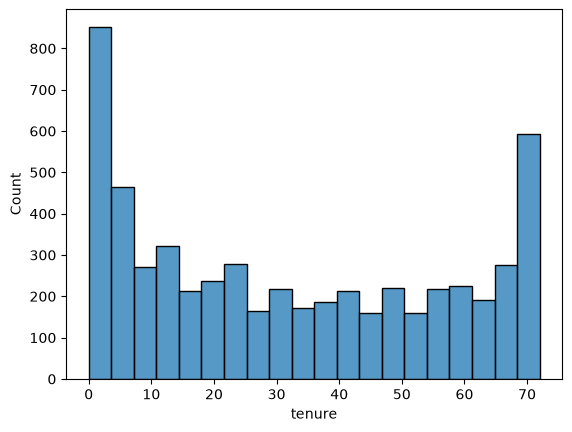

In [98]:
sns.histplot(df_full_train.tenure, bins=20)

In [99]:
df_full_train[df_full_train.tenure <= 2].churn.mean()

np.float64(0.5953420669577875)

In [100]:
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()

np.float64(0.3994413407821229)

In [101]:
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

*The pattern is striking. Customers who have been with the company for two months or less churn at almost 60%. For customers of up to a year it is about 40%, and for those who stayed longer than a year only about 18%. Churn clearly decreases as tenure grows - exactly what the negative correlation told us.*

/tmp/ipykernel_4803/1959810863.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(tenure_dict,palette="light:#5A9",legend=False)


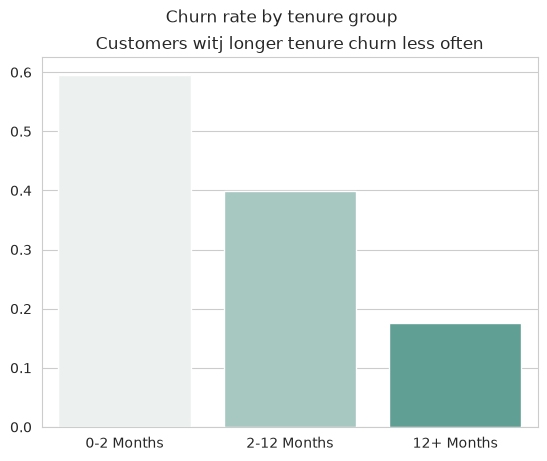

In [120]:
tenure_dict = {'0-2 Months':df_full_train[df_full_train.tenure <= 2].churn.mean(),
               '2-12 Months': df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean(),
               '12+ Months': df_full_train[df_full_train.tenure > 12].churn.mean()}

with sns.axes_style("whitegrid"):
    sns.barplot(tenure_dict,palette="light:#5A9",legend=False)
    plt.suptitle('Churn rate by tenure group')
    plt.title('Customers with longer tenure churn less often')

In [121]:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

np.float64(0.08795411089866156)

In [122]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

np.float64(0.18340943683409436)

In [123]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()

np.float64(0.32499341585462205)